# Lecture 4 companion: quality decisions, maintenance, and sensor feedback

**15–20 minute instructor demonstration.** Before moving any slider, predict what will happen and say why. All data, costs, and machines are synthetic; no files or downloads are required. This complements the larger decision models in [the automation and robotics labs](https://github.com/AdoHaha/automation_robotics_lab).

1. Turn scores into probabilities and probabilities into cost-sensitive diversion decisions (7 min).
2. Choose maintenance with one available crew slot (3 min).
3. See how a biased sensor makes a controller move the true process away from its target (5 min).

Run all cells in order. Required: `numpy scipy pandas matplotlib`; `ipywidgets` is optional. In a fresh environment, install these with `%pip install numpy scipy pandas matplotlib ipywidgets`. Every widget also has a direct function call below it, so the lesson works in plain Jupyter and exported static notebooks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit
from scipy.optimize import minimize
from IPython.display import display
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})

## 1. A fixed model, a later calibration period, and a future test period

A synthetic scoring model already exists. Its raw score is deliberately distorted: $s=\sqrt{p_0}$, where $p_0$ is the baseline generator's probability. This transformation preserves ranking but inflates scores. We fit a two-parameter sigmoid calibration map on **earlier validation data only**. The known generator probability is a teaching aid, never an input to calibration.

Rows 0–2999 represent earlier validation parts and 3000–5999 later test parts. A test-period log-odds shift represents a new defect prevalence after calibration. The predictor remains fixed; the later outcome distribution changes. This isolates calibration and drift rather than introducing a model-training tutorial. A real project would also need an earlier model-training period and grouped splits for repeated parts/batches.

In [2]:
def quality_data(test_log_odds_shift=0.0, seed=404):
    rng = np.random.default_rng(seed)
    n = 6000
    feature = rng.normal(size=n)
    base_log_odds = -3.0 + 1.1 * feature
    actual_log_odds = base_log_odds.copy()
    actual_log_odds[n//2:] += test_log_odds_shift
    true_probability = expit(actual_log_odds)
    y = rng.binomial(1, true_probability)
    return pd.DataFrame({'part_time': np.arange(n), 'feature': feature,
                         'raw_score': np.sqrt(expit(base_log_odds)),
                         'true_probability': true_probability, 'defect': y,
                         'period': ['validation']*(n//2) + ['test']*(n//2)})

def fit_sigmoid_calibrator(validation):
    z = logit(np.clip(validation.raw_score.to_numpy(), 1e-8, 1-1e-8))
    y = validation.defect.to_numpy()
    X = np.column_stack([np.ones(len(z)), z])
    def objective(theta):
        eta = X @ theta
        return np.mean(np.logaddexp(0, eta) - y * eta)
    def gradient(theta):
        return X.T @ (expit(X @ theta) - y) / len(y)
    result = minimize(objective, [0.0, 1.0], jac=gradient, method='BFGS',
                      options={'gtol': 1e-8})
    assert result.success, result.message
    return result.x

def apply_calibrator(scores, theta):
    return expit(theta[0] + theta[1]*logit(np.clip(scores, 1e-8, 1-1e-8)))

def policy_metrics(y, p, threshold, missed_cost=200, false_divert_cost=10):
    y, p = np.asarray(y), np.asarray(p)
    divert = p > threshold
    tp = int(np.sum(divert & (y == 1)))
    fp = int(np.sum(divert & (y == 0)))
    fn = int(np.sum(~divert & (y == 1)))
    tn = int(np.sum(~divert & (y == 0)))
    return {'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'diverted': int(divert.sum()),
            'recall': tp / max(tp+fn, 1), 'precision': tp / max(tp+fp, 1),
            'cost_PLN_per_1000': 1000*(fp*false_divert_cost + fn*missed_cost)/len(y),
            'Brier': float(np.mean((p-y)**2))}

def reliability_bins(y, p, bins=8):
    frame = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    # Equal-count bins keep bin support visible for a rare event.
    frame['bin'] = pd.qcut(frame.p, bins, duplicates='drop')
    return frame.groupby('bin', observed=True).agg(mean_p=('p','mean'),
               defect_fraction=('y','mean'), count=('y','size'))

### Predict: if a missed defect costs more, what should happen?

With only false-diversion cost $c_{FP}$ and missed-defect cost $c_{FN}$,

$$C(\text{accept})=p c_{FN},\quad C(\text{divert})=(1-p)c_{FP},\quad
\text{divert if }p>\frac{c_{FP}}{c_{FP}+c_{FN}}.$$

We charge zero incremental cost for correct decisions. This is **not** an inspection fee charged on every diverted part. The threshold follows from the specified cost model; it is not tuned on test labels. The test cost curves below are retrospective diagnostics, not a new threshold-selection step.

Cost-derived threshold: 0.0476; observed test prevalence: 7.867%


,TP,FP,FN,TN,diverted,recall,precision,cost_PLN_per_1000,Brier
Raw score used as probability,236.0,2757.0,0.0,7.0,2993.0,1.000,0.079,9190.000,0.097
Earlier calibrated probability,201.0,1321.0,35.0,1443.0,1522.0,0.852,0.132,6736.667,0.067
Accept everything,0.0,0.0,236.0,2764.0,0.0,0.000,0.000,15733.333,NaN
Divert everything,236.0,2764.0,0.0,0.0,3000.0,1.000,0.079,9213.333,NaN


Calibration bin counts (earlier calibrated test probabilities):


,mean_p,defect_fraction,count
bin,,,
"(0.0010600000000000002, 0.0177]",0.012,0.011,375
"(0.0177, 0.0266]",0.022,0.016,375
"(0.0266, 0.0366]",0.032,0.035,375
"(0.0366, 0.0485]",0.042,0.032,375
"(0.0485, 0.0662]",0.057,0.069,375
"(0.0662, 0.0915]",0.078,0.085,375
"(0.0915, 0.145]",0.114,0.139,375
"(0.145, 0.772]",0.248,0.243,375


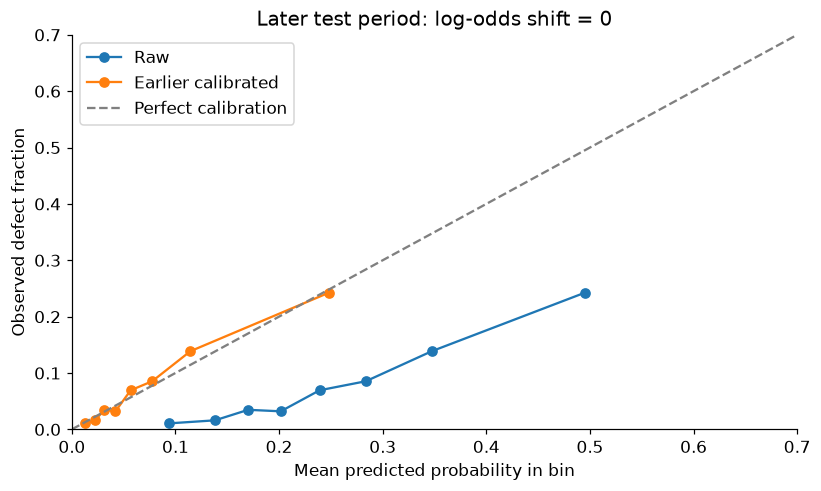

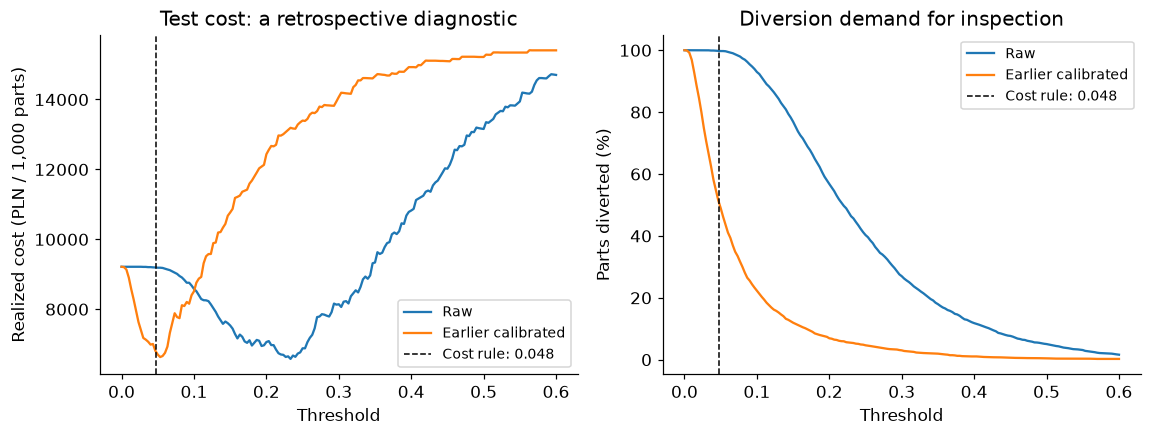

In [3]:
def run_quality_demo(missed_cost=200, false_divert_cost=10,
                     test_log_odds_shift=0.0, show=True):
    data = quality_data(test_log_odds_shift)
    validation = data[data.period == 'validation']
    test = data[data.period == 'test']
    theta = fit_sigmoid_calibrator(validation)
    raw = test.raw_score.to_numpy()
    calibrated = apply_calibrator(raw, theta)
    y = test.defect.to_numpy()
    threshold = false_divert_cost / (false_divert_cost + missed_cost)
    rows = {name: policy_metrics(y, p, threshold, missed_cost, false_divert_cost)
            for name, p in [('Raw score used as probability', raw),
                            ('Earlier calibrated probability', calibrated)]}
    # Baselines use scores 0 and 1 to force constant decisions.
    rows['Accept everything'] = policy_metrics(y, np.zeros(len(y)), threshold,
                                               missed_cost, false_divert_cost)
    rows['Divert everything'] = policy_metrics(y, np.ones(len(y)), threshold,
                                               missed_cost, false_divert_cost)
    metrics = pd.DataFrame(rows).T
    # Forced-action baselines are policies, not probability forecasts.
    metrics.loc[['Accept everything','Divert everything'], 'Brier'] = np.nan
    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    for name, p in [('Raw', raw), ('Earlier calibrated', calibrated)]:
        b = reliability_bins(y, p)
        ax.plot(b.mean_p, b.defect_fraction, 'o-', label=name)
    ax.plot([0, .7], [0, .7], '--', color='0.5', label='Perfect calibration')
    ax.set(xlabel='Mean predicted probability in bin', ylabel='Observed defect fraction',
           title=f'Later test period: log-odds shift = {test_log_odds_shift:g}',
           xlim=(0,.7), ylim=(0,.7))
    ax.legend(); fig.tight_layout()
    cost_fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.1))
    grid = np.linspace(0, .6, 181)
    for name, p in [('Raw', raw), ('Earlier calibrated', calibrated)]:
        cost = [policy_metrics(y,p,t,missed_cost,false_divert_cost)['cost_PLN_per_1000']
                for t in grid]
        diversion = [100*np.mean(p>t) for t in grid]
        axes[0].plot(grid, cost, label=name)
        axes[1].plot(grid, diversion, label=name)
    for a in axes:
        a.axvline(threshold, color='black', ls='--', lw=1,
                  label=f'Cost rule: {threshold:.3f}')
        a.set(xlabel='Threshold'); a.legend(fontsize=9)
    axes[0].set(ylabel='Realized cost (PLN / 1,000 parts)', title='Test cost: a retrospective diagnostic')
    axes[1].set(ylabel='Parts diverted (%)', title='Diversion demand for inspection')
    cost_fig.tight_layout()
    if show:
        print(f'Cost-derived threshold: {threshold:.4f}; observed test prevalence: {y.mean():.3%}')
        display(metrics.round(3))
        print('Calibration bin counts (earlier calibrated test probabilities):')
        display(reliability_bins(y, calibrated).round(3))
        plt.show()
    return {'metrics': metrics, 'threshold': threshold, 'data': data,
            'calibrated_test': calibrated, 'calibration_figure': fig,
            'cost_figure': cost_fig}

baseline_quality = run_quality_demo()

**Interpretation.** An inflated raw score diverts too many good parts at the cost-derived probability threshold. Earlier calibration should reduce this cost in the unchanged population. The threshold applies to probabilities; ranking alone cannot justify it.

The raw and calibrated curves need not have the same realized minimum at exactly the analytical threshold: this is a finite random sample and calibration is imperfect. Selecting the most flattering test minimum would reuse test labels for policy tuning.

In [4]:
# Optional live controls. Direct fallback: run_quality_demo(400, 10, 0.8)
try:
    import ipywidgets as widgets
except ImportError:
    print('ipywidgets unavailable: call run_quality_demo(...) directly.')
else:
    quality_controls = widgets.interactive(
        run_quality_demo,
        missed_cost=widgets.IntSlider(value=200,min=50,max=600,step=50,
                                     description='Miss cost', continuous_update=False),
        false_divert_cost=widgets.IntSlider(value=10,min=5,max=40,step=5,
                                            description='False divert', continuous_update=False),
        test_log_odds_shift=widgets.FloatSlider(value=0,min=-1,max=1.5,step=.25,
                                                description='Later shift', continuous_update=False),
        show=widgets.fixed(True))
    display(quality_controls)

interactive(children=(IntSlider(value=200, continuous_update=False, description='Miss cost', max=600, min=50, …

**Try and explain:** keep costs fixed and set the later log-odds shift to 1.0. The older calibrator has never seen the new prevalence. On the reliability plot, observed defects should now lie above predicted probabilities. A score-distribution shift is not required: features and the fixed scoring rule have not changed. Delayed labels reveal the change in performance.

An intervention can also change labels. If only diverted parts receive independent inspection, this test table would be selectively observed. Retain a representative audit sample of accepted parts.

## 2. Maintenance: prediction plus intervention assumptions

A seven-day failure costs 10,000 PLN. Preventive maintenance costs 600 PLN and initially eliminates failure within the horizon. With one crew slot, service the machine with the highest positive expected net saving.

In [5]:
def maintenance_decision(crew_slots=1, residual_probability=0.0):
    table = pd.DataFrame({'machine':['A','B','C'], 'failure_probability':[.02,.08,.15]})
    table['wait_cost_PLN'] = 10000*table.failure_probability
    table['maintain_cost_PLN'] = 600 + 10000*residual_probability
    table['net_saving_PLN'] = table.wait_cost_PLN - table.maintain_cost_PLN
    order = table[table.net_saving_PLN > 0].sort_values('net_saving_PLN',ascending=False).index
    table['maintain'] = False
    table.loc[order[:crew_slots], 'maintain'] = True
    return table

maintenance = maintenance_decision()
display(maintenance)
print('Policy expected cost:', np.where(maintenance.maintain,
      maintenance.maintain_cost_PLN,maintenance.wait_cost_PLN).sum(), 'PLN')

,machine,failure_probability,wait_cost_PLN,maintain_cost_PLN,net_saving_PLN,maintain
0,A,0.02,200.0,600.0,-400.0,False
1,B,0.08,800.0,600.0,200.0,False
2,C,0.15,1500.0,600.0,900.0,True


Policy expected cost: 1600.0 PLN


**Answer:** service C, saving 900 PLN relative to waiting. With two slots, also service B. The expected total cost with one slot is $200+800+600=1,600$ PLN, versus $2,500$ PLN if all wait.

**Check:** call `maintenance_decision(2, .03)`. Maintenance now leaves a 3% failure probability. B no longer has a positive net saving: its avoided expected loss is only 500 PLN. This demonstrates why prediction quality alone does not establish the effect of maintenance. The common residual-risk assumption is simplified; actual intervention effects depend on machine condition.

## 3. Sensor feedback: when the display looks fine

A scalar process follows $x_{t+1}=x_t+0.15(u_t-x_t)+w_t$. The sensor reports $z_t=x_t+b_t+\epsilon_t$. A proportional controller commands $u_t=r+K(r-z_t)$, with actuator limits $[0,2]$. At step 70, the sensor develops a constant positive bias.

**Predict:** will the true process move above or below its target? Will increasing the gain remove the sensor bias?

Expected noiseless true equilibrium: 0.800; last 20-step true mean: 0.800


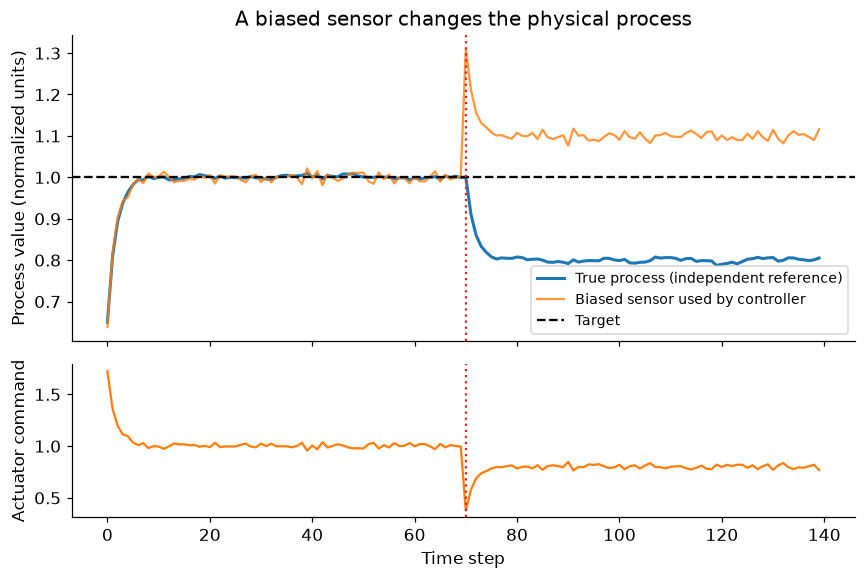

In [6]:
def sensor_feedback(sensor_bias=.3, gain=2.0, show=True):
    rng = np.random.default_rng(441)
    n, target = 140, 1.0
    x = np.zeros(n); z = np.zeros(n); u = np.zeros(n)
    x[0] = .65
    for t in range(n):
        bias = sensor_bias if t >= 70 else 0.0
        z[t] = x[t] + bias + rng.normal(0, .008)
        u[t] = np.clip(target + gain*(target-z[t]), 0, 2)
        if t+1 < n:
            x[t+1] = x[t] + .15*(u[t]-x[t]) + rng.normal(0, .003)
    fig, axes = plt.subplots(2,1,figsize=(8,5.4),sharex=True,
                             gridspec_kw={'height_ratios':[2,1]})
    axes[0].plot(x,label='True process (independent reference)',lw=2)
    axes[0].plot(z,label='Biased sensor used by controller',alpha=.8)
    axes[0].axhline(target,color='black',ls='--',label='Target')
    axes[0].set(ylabel='Process value (normalized units)',title='A biased sensor changes the physical process')
    axes[0].legend(fontsize=9,loc='lower right')
    axes[1].plot(u,color='tab:orange'); axes[1].set(xlabel='Time step',ylabel='Actuator command')
    for ax in axes: ax.axvline(70,color='tab:red',ls=':',label='Bias begins')
    fig.tight_layout()
    equilibrium = target - gain*sensor_bias/(1+gain)
    if show:
        print(f'Expected noiseless true equilibrium: {equilibrium:.3f}; '
              f'last 20-step true mean: {x[-20:].mean():.3f}')
        plt.show()
    return {'true':x,'sensor':z,'command':u,'equilibrium':equilibrium,'figure':fig}

sensor_result = sensor_feedback()

In [7]:
# Optional controls; direct fallback: sensor_feedback(sensor_bias=.5, gain=3)
try:
    import ipywidgets as widgets
except ImportError:
    print('Call sensor_feedback(...) directly.')
else:
    display(widgets.interactive(sensor_feedback,
        sensor_bias=widgets.FloatSlider(value=.3,min=0,max=.6,step=.1,
                                        description='Sensor bias',continuous_update=False),
        gain=widgets.FloatSlider(value=2,min=.5,max=4,step=.5,
                                 description='Gain',continuous_update=False),
        show=widgets.fixed(True)))

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='Sensor bias', max=0.6), Flo…

**Answer and derivation.** With no noise or saturation, equilibrium requires $x=u=r+K(r-x-b)$, so

$$x^*=r-\frac{K}{1+K}b,\qquad z^*=r+\frac{b}{1+K}.$$

For $K=2$ and $b=0.3$, the true process settles near 0.8 while the display reads near 1.1. Increasing gain moves the display closer to 1.0 and the true process closer to 0.7. It does not identify or remove the bias. The supported gain range keeps the unsaturated scalar dynamics stable: $|1-0.15(1+K)|<1$.

This is a simple control demonstration, not a learned controller or a safety design. Independent reference measurements, sensor checks, and validated fallback behavior are needed before a predictive model is allowed to influence equipment.

In [8]:
# Numeric checks: decisions, cost accounting, calibration separation, and feedback.
assert np.isclose(baseline_quality['threshold'], 10/210)
assert np.isclose(policy_metrics([1]*20+[0]*980, [0]*1000, .05)['cost_PLN_per_1000'],4000)
example_y = np.array([1]*18+[0]*40+[1]*2+[0]*940)
example_scores = np.array([1]*58+[0]*942)
example = policy_metrics(example_y, example_scores, .05)
assert (example['TP'],example['FP'],example['FN'],example['TN']) == (18,40,2,940)
assert example['cost_PLN_per_1000'] == 800
assert baseline_quality['metrics'].loc['Earlier calibrated probability','Brier'] < baseline_quality['metrics'].loc['Raw score used as probability','Brier']
assert maintenance.loc[maintenance.maintain,'machine'].tolist() == ['C']
assert maintenance_decision(2,.03).loc[lambda x:x.maintain,'machine'].tolist() == ['C']
assert abs(sensor_result['true'][-20:].mean()-.8) < .03
print('All lecture-example and simulation checks passed.')

All lecture-example and simulation checks passed.


## Discussion and transfer to the labs

- More expensive missed defects lower the cost-derived threshold and increase diversion demand. A capacity constraint may require selecting the highest positive expected benefits.
- Calibration fitted before a prevalence change can fail after it. Assess later outcomes, not just the distribution of scores.
- Failure horizon, censoring, intervention effectiveness, and crew capacity determine the maintenance policy.
- A biased sensor can corrupt physical behavior even when its own readings look reassuring.

The larger laboratories develop optimization models. This companion makes explicit what those models need from a prediction system: a defined event and horizon, calibrated uncertainty, action costs, capacity, and a plausible account of what the intervention changes.

Sources: [scikit-learn probability calibration](https://scikit-learn.org/stable/modules/calibration.html) and [time-series cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split). Brier score mixes calibration, discrimination, and outcome uncertainty; it is not a standalone calibration test. Plotted bin estimates depend on finite sample counts.